In [90]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv(r"C:\Users\SuNi\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [91]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [92]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].apply(type).value_counts()

TotalCharges
<class 'float'>    7043
Name: count, dtype: int64

In [93]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].mean())
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [94]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2265.000258
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1400.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


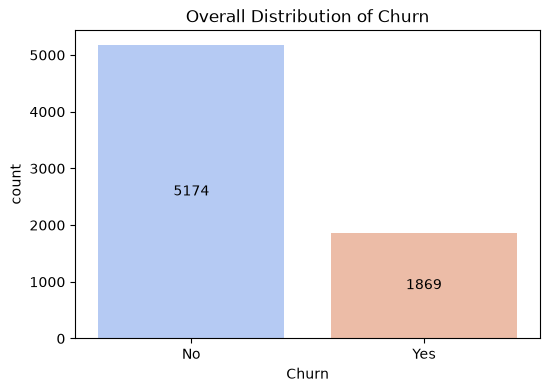

In [95]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=df['Churn'], palette='coolwarm')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title("Overall Distribution of Churn")
plt.show()

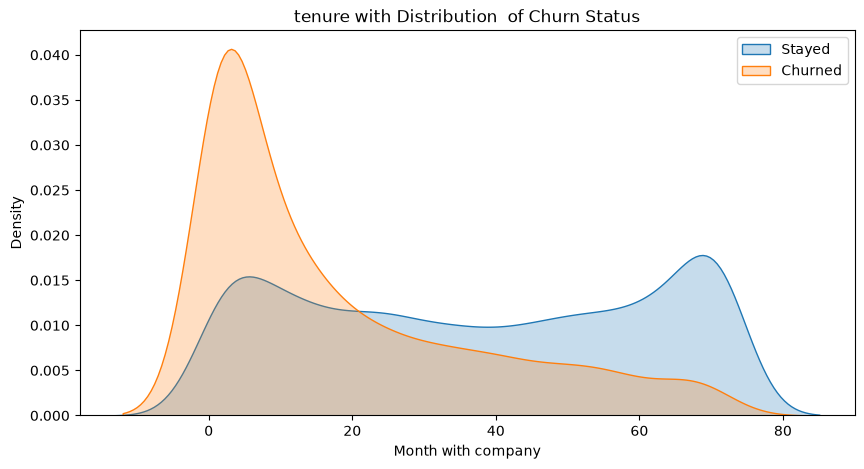

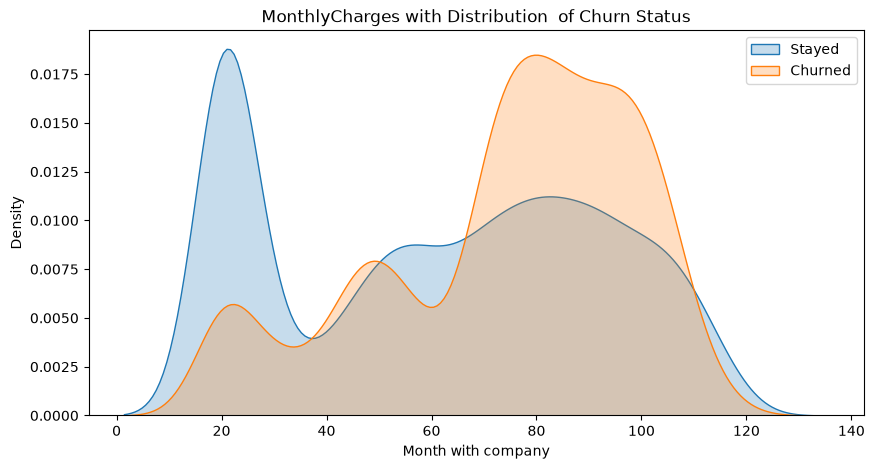

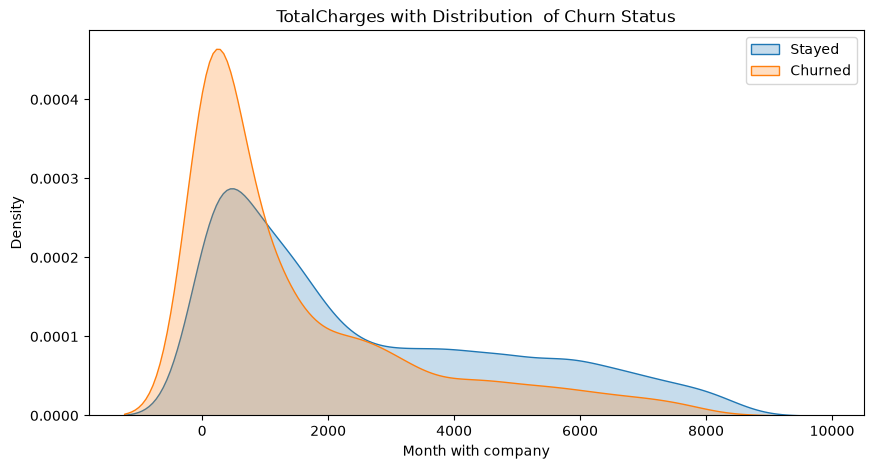

In [96]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    plt.figure(figsize=(10, 5))
    sns.kdeplot(df[df['Churn']=='No'][col], label='Stayed', shade=True)
    sns.kdeplot(df[df['Churn']=='Yes'][col], label='Churned', shade=True)
    plt.title(f'{col} with Distribution  of Churn Status')
    plt.xlabel('Month with company')
    plt.legend()
    plt.show()

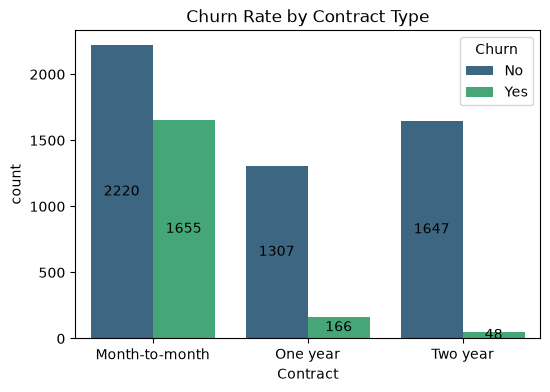

In [97]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=df['Contract'], hue=df['Churn'], palette='viridis')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title("Churn Rate by Contract Type")
plt.show()

In [98]:
word_cols = ['gender', 'Partner', 'Dependents', 'PhoneService','MultipleLines', 'InternetService',
'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
'Contract', 'PaperlessBilling', 'PaymentMethod','Churn']

for col in word_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

encoder = []
for col in word_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col].astype(str))

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,3668-QPYBK,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


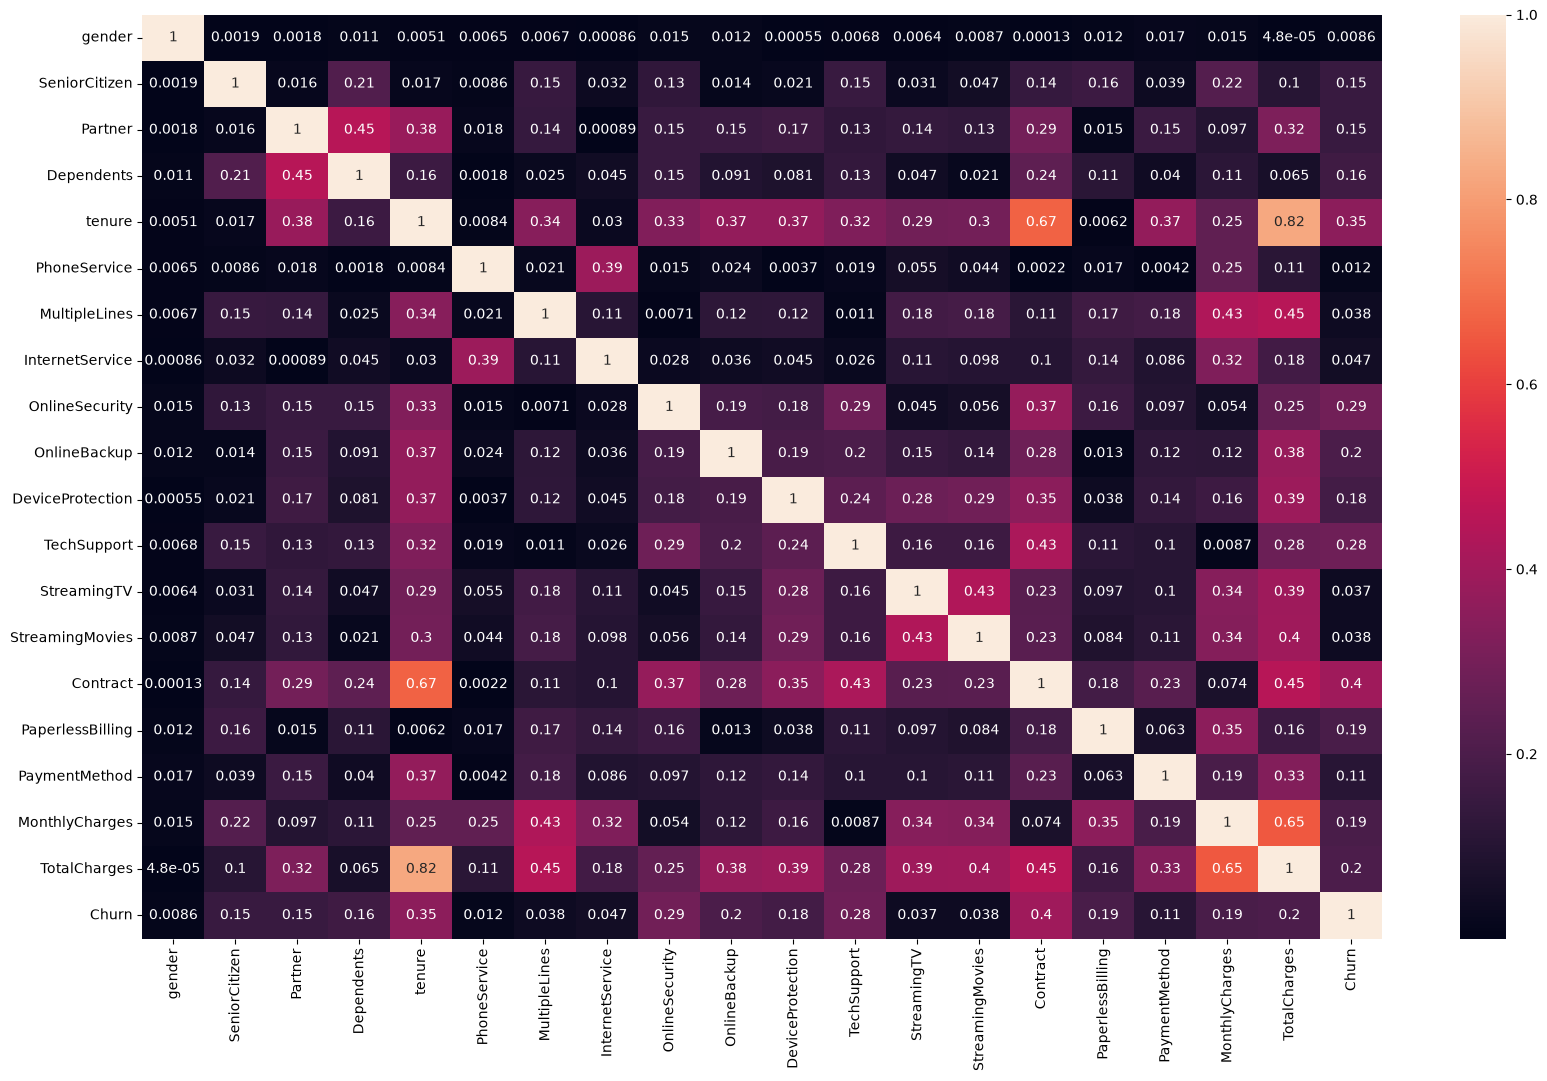

In [99]:
plt.figure(figsize=(20, 12))
corr = abs(df.corr(numeric_only=True))
sns.heatmap(corr, annot=True)
plt.show()

In [100]:
X = df.drop([ 'customerID','Churn'], axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

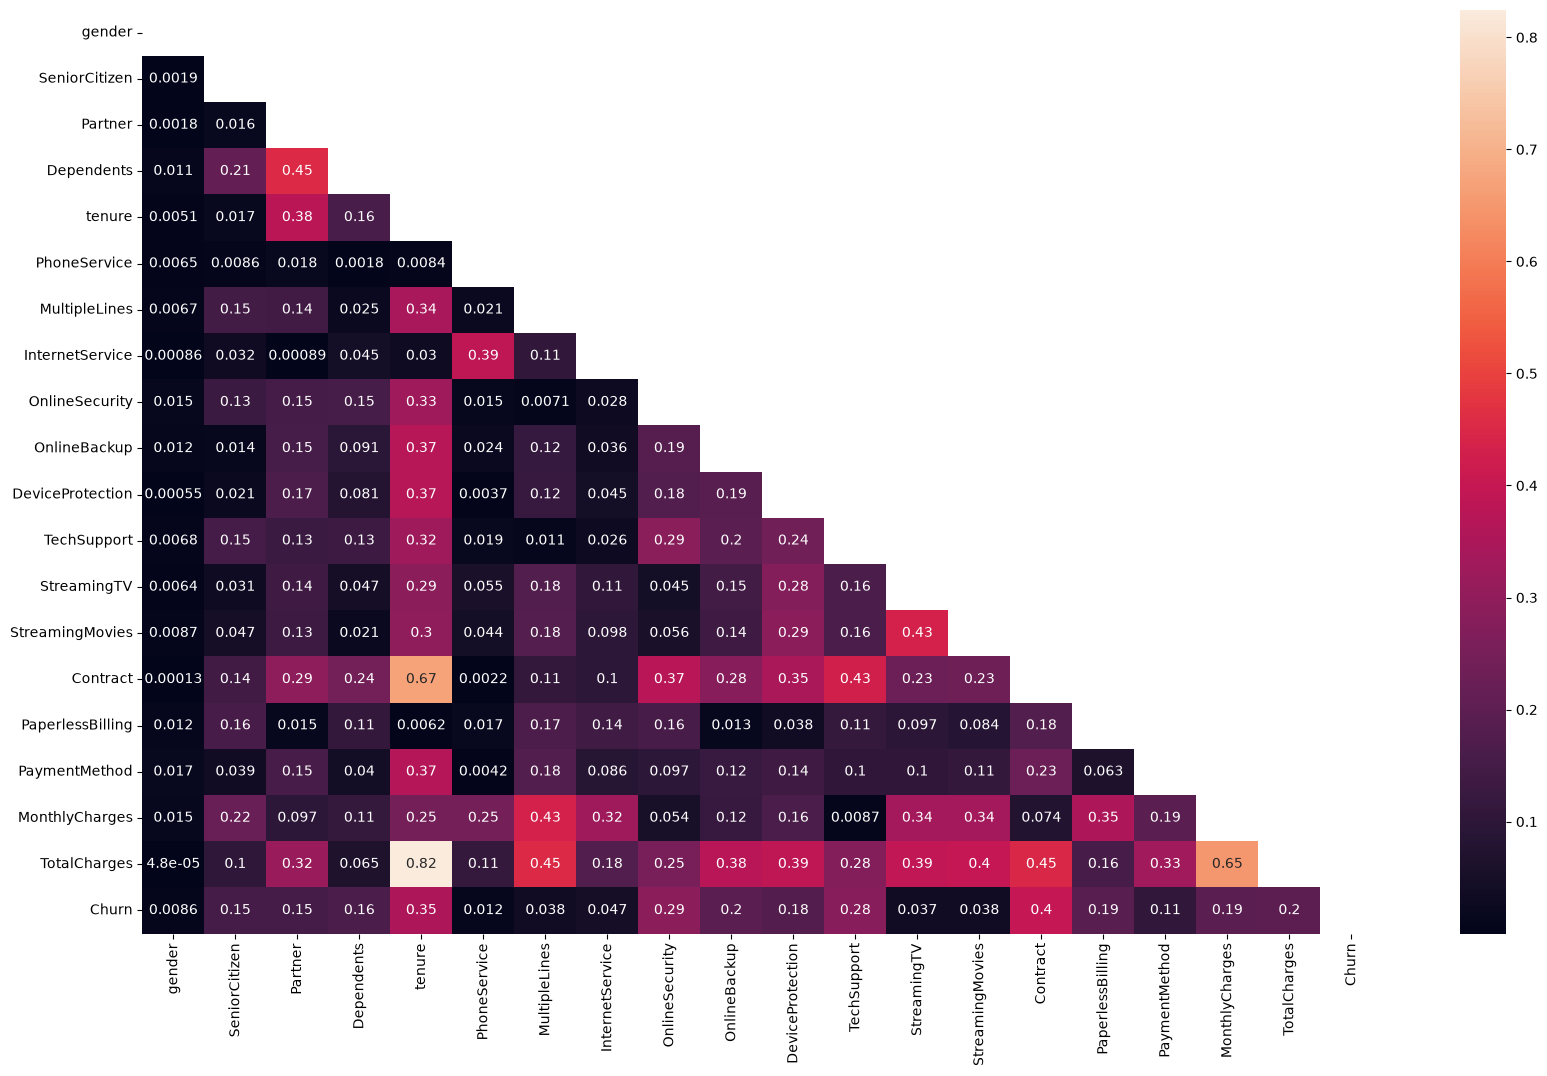

In [101]:
plt.figure(figsize=(20, 12))
corr = abs(df.corr(numeric_only=True))
mask = np.zeros_like(corr)
mask[np.triu_indices_from(mask)]=True
sns.heatmap(corr, annot=True, mask=mask)
plt.show()

In [102]:
models = {
    'Random Forest': RandomForestClassifier(),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred=m.predict(X_test)
    print(f'\n---{name}---')
    print(f"Overall Accuracy: {accuracy_score(y_test, pred):.2f}")
    print(f'Confusion Matrix:\n{confusion_matrix(y_test, pred)}')
    print(f'Classification Report:\n{classification_report(y_test, pred)}')


---Random Forest---
Overall Accuracy: 0.78
Confusion Matrix:
[[925 116]
 [187 181]]
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1041
           1       0.61      0.49      0.54       368

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



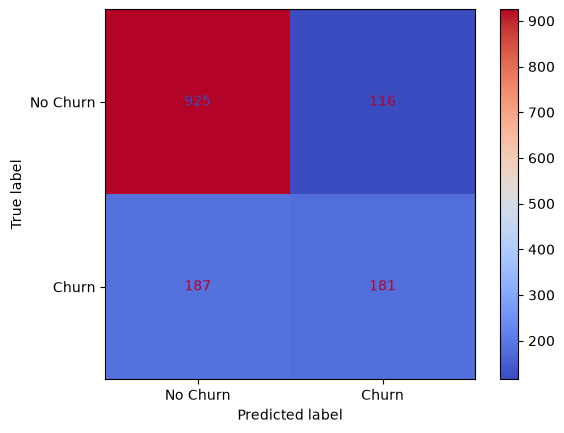

In [103]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(cmap='coolwarm')
plt.show()